In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [2]:
# Load the data
df = pd.read_excel('Assignment.xlsx')
df.head()

,Previous Complexity Level,Current Complexity Level,Previous Cognitive Level,Current Quiz Cognitive Level,Proposed Question Type
0,1,1,Slow,Slow,Basic
1,1,1,Slow,Medium,Intermediate
2,1,1,Slow,Fast,Intermediate
3,1,1,Medium,Slow,Basic
4,1,1,Medium,Medium,Intermediate


In [3]:
# Split the features and target variable
X = df[['Previous Complexity Level', 'Current Complexity Level', 'Previous Cognitive Level', 'Current Quiz Cognitive Level']]
y = df['Proposed Question Type']

# One-hot encode the categorical columns
categorical_columns = ['Previous Cognitive Level', 'Current Quiz Cognitive Level']
encoder = OneHotEncoder(sparse=False)

# Prepare the preprocessing pipeline: scale numerical features and one-hot encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['Previous Complexity Level', 'Current Complexity Level']),
        ('cat', encoder, categorical_columns)
    ])

In [4]:
# Split the features and target variable
X = df[['Previous Complexity Level', 'Current Complexity Level', 'Previous Cognitive Level', 'Current Quiz Cognitive Level']]
y = df['Proposed Question Type']


In [5]:
# One-hot encode the categorical columns
categorical_columns = ['Previous Cognitive Level', 'Current Quiz Cognitive Level']
encoder = OneHotEncoder(sparse=False)

# Prepare the preprocessing pipeline: scale numerical features and one-hot encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['Previous Complexity Level', 'Current Complexity Level']),
        ('cat', encoder, categorical_columns)
    ])


In [6]:
# Apply preprocessing steps to data
X_processed = preprocessor.fit_transform(X)


/usr/local/lib/python3.10/dist-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


In [7]:
# One-hot encode the target (Proposed Question Type)
y_encoded = pd.get_dummies(y)


In [8]:
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_processed, y_encoded, test_size=0.2, random_state=42)


In [9]:
# Build the model
model = tf.keras.Sequential([
    tf.keras.layers.InputLayer(input_shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(y_encoded.shape[1], activation='softmax')
])


In [10]:
# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                576       
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dense_2 (Dense)             (None, 3)                 99        
                                                                 
Total params: 2755 (10.76 KB)
Trainable params: 2755 (10.76 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [11]:
# Train the model
history = model.fit(X_train, y_train, epochs=500, batch_size=8, validation_data=(X_test, y_test))


Epoch 1/500
8/8 [==============================] - 1s 21ms/step - loss: 1.1167 - accuracy: 0.4062 - val_loss: 1.0871 - val_accuracy: 0.4118
Epoch 2/500
8/8 [==============================] - 0s 4ms/step - loss: 1.0419 - accuracy: 0.4531 - val_loss: 1.0250 - val_accuracy: 0.4118
Epoch 3/500
8/8 [==============================] - 0s 4ms/step - loss: 0.9876 - accuracy: 0.4844 - val_loss: 0.9715 - val_accuracy: 0.4118
Epoch 4/500
8/8 [==============================] - 0s 4ms/step - loss: 0.9368 - accuracy: 0.5312 - val_loss: 0.9189 - val_accuracy: 0.4118
Epoch 5/500
8/8 [==============================] - 0s 4ms/step - loss: 0.8889 - accuracy: 0.6406 - val_loss: 0.8632 - val_accuracy: 0.4706
Epoch 6/500
8/8 [==============================] - 0s 4ms/step - loss: 0.8394 - accuracy: 0.7500 - val_loss: 0.8046 - val_accuracy: 0.7647
Epoch 7/500
8/8 [==============================] - 0s 4ms/step - loss: 0.7855 - accuracy: 0.7969 - val_loss: 0.7492 - val_accuracy: 0.8824
Epoch 8/500
8/8 [=========

8/8 [==============================] - 0s 4ms/step - loss: 0.0104 - accuracy: 1.0000 - val_loss: 0.0208 - val_accuracy: 1.0000
Epoch 60/500
8/8 [==============================] - 0s 4ms/step - loss: 0.0100 - accuracy: 1.0000 - val_loss: 0.0201 - val_accuracy: 1.0000
Epoch 61/500
8/8 [==============================] - 0s 4ms/step - loss: 0.0096 - accuracy: 1.0000 - val_loss: 0.0195 - val_accuracy: 1.0000
Epoch 62/500
8/8 [==============================] - 0s 4ms/step - loss: 0.0091 - accuracy: 1.0000 - val_loss: 0.0191 - val_accuracy: 1.0000
Epoch 63/500
8/8 [==============================] - 0s 4ms/step - loss: 0.0087 - accuracy: 1.0000 - val_loss: 0.0183 - val_accuracy: 1.0000
Epoch 64/500
8/8 [==============================] - 0s 4ms/step - loss: 0.0084 - accuracy: 1.0000 - val_loss: 0.0177 - val_accuracy: 1.0000
Epoch 65/500
8/8 [==============================] - 0s 4ms/step - loss: 0.0081 - accuracy: 1.0000 - val_loss: 0.0171 - val_accuracy: 1.0000
Epoch 66/500
8/8 [===============

8/8 [==============================] - 0s 4ms/step - loss: 0.0018 - accuracy: 1.0000 - val_loss: 0.0052 - val_accuracy: 1.0000
Epoch 118/500
8/8 [==============================] - 0s 4ms/step - loss: 0.0018 - accuracy: 1.0000 - val_loss: 0.0052 - val_accuracy: 1.0000
Epoch 119/500
8/8 [==============================] - 0s 4ms/step - loss: 0.0018 - accuracy: 1.0000 - val_loss: 0.0051 - val_accuracy: 1.0000
Epoch 120/500
8/8 [==============================] - 0s 4ms/step - loss: 0.0017 - accuracy: 1.0000 - val_loss: 0.0050 - val_accuracy: 1.0000
Epoch 121/500
8/8 [==============================] - 0s 4ms/step - loss: 0.0017 - accuracy: 1.0000 - val_loss: 0.0049 - val_accuracy: 1.0000
Epoch 122/500
8/8 [==============================] - 0s 4ms/step - loss: 0.0017 - accuracy: 1.0000 - val_loss: 0.0048 - val_accuracy: 1.0000
Epoch 123/500
8/8 [==============================] - 0s 4ms/step - loss: 0.0016 - accuracy: 1.0000 - val_loss: 0.0047 - val_accuracy: 1.0000
Epoch 124/500
8/8 [========

8/8 [==============================] - 0s 4ms/step - loss: 7.0903e-04 - accuracy: 1.0000 - val_loss: 0.0023 - val_accuracy: 1.0000
Epoch 175/500
8/8 [==============================] - 0s 4ms/step - loss: 6.9915e-04 - accuracy: 1.0000 - val_loss: 0.0023 - val_accuracy: 1.0000
Epoch 176/500
8/8 [==============================] - 0s 4ms/step - loss: 6.8970e-04 - accuracy: 1.0000 - val_loss: 0.0023 - val_accuracy: 1.0000
Epoch 177/500
8/8 [==============================] - 0s 4ms/step - loss: 6.7906e-04 - accuracy: 1.0000 - val_loss: 0.0022 - val_accuracy: 1.0000
Epoch 178/500
8/8 [==============================] - 0s 4ms/step - loss: 6.7103e-04 - accuracy: 1.0000 - val_loss: 0.0022 - val_accuracy: 1.0000
Epoch 179/500
8/8 [==============================] - 0s 4ms/step - loss: 6.6328e-04 - accuracy: 1.0000 - val_loss: 0.0022 - val_accuracy: 1.0000
Epoch 180/500
8/8 [==============================] - 0s 4ms/step - loss: 6.5185e-04 - accuracy: 1.0000 - val_loss: 0.0022 - val_accuracy: 1.0000

8/8 [==============================] - 0s 4ms/step - loss: 3.5804e-04 - accuracy: 1.0000 - val_loss: 0.0013 - val_accuracy: 1.0000
Epoch 231/500
8/8 [==============================] - 0s 4ms/step - loss: 3.5433e-04 - accuracy: 1.0000 - val_loss: 0.0013 - val_accuracy: 1.0000
Epoch 232/500
8/8 [==============================] - 0s 4ms/step - loss: 3.5084e-04 - accuracy: 1.0000 - val_loss: 0.0013 - val_accuracy: 1.0000
Epoch 233/500
8/8 [==============================] - 0s 4ms/step - loss: 3.4714e-04 - accuracy: 1.0000 - val_loss: 0.0013 - val_accuracy: 1.0000
Epoch 234/500
8/8 [==============================] - 0s 4ms/step - loss: 3.4317e-04 - accuracy: 1.0000 - val_loss: 0.0012 - val_accuracy: 1.0000
Epoch 235/500
8/8 [==============================] - 0s 4ms/step - loss: 3.3927e-04 - accuracy: 1.0000 - val_loss: 0.0012 - val_accuracy: 1.0000
Epoch 236/500
8/8 [==============================] - 0s 4ms/step - loss: 3.3619e-04 - accuracy: 1.0000 - val_loss: 0.0012 - val_accuracy: 1.0000

Epoch 286/500
8/8 [==============================] - 0s 4ms/step - loss: 2.0686e-04 - accuracy: 1.0000 - val_loss: 8.1121e-04 - val_accuracy: 1.0000
Epoch 287/500
8/8 [==============================] - 0s 4ms/step - loss: 2.0479e-04 - accuracy: 1.0000 - val_loss: 8.0315e-04 - val_accuracy: 1.0000
Epoch 288/500
8/8 [==============================] - 0s 4ms/step - loss: 2.0355e-04 - accuracy: 1.0000 - val_loss: 7.9236e-04 - val_accuracy: 1.0000
Epoch 289/500
8/8 [==============================] - 0s 4ms/step - loss: 2.0116e-04 - accuracy: 1.0000 - val_loss: 7.8748e-04 - val_accuracy: 1.0000
Epoch 290/500
8/8 [==============================] - 0s 4ms/step - loss: 1.9938e-04 - accuracy: 1.0000 - val_loss: 7.8346e-04 - val_accuracy: 1.0000
Epoch 291/500
8/8 [==============================] - 0s 4ms/step - loss: 1.9774e-04 - accuracy: 1.0000 - val_loss: 7.7595e-04 - val_accuracy: 1.0000
Epoch 292/500
8/8 [==============================] - 0s 4ms/step - loss: 1.9601e-04 - accuracy: 1.0000 - v

Epoch 341/500
8/8 [==============================] - 0s 4ms/step - loss: 1.3025e-04 - accuracy: 1.0000 - val_loss: 5.4360e-04 - val_accuracy: 1.0000
Epoch 342/500
8/8 [==============================] - 0s 4ms/step - loss: 1.2912e-04 - accuracy: 1.0000 - val_loss: 5.3975e-04 - val_accuracy: 1.0000
Epoch 343/500
8/8 [==============================] - 0s 4ms/step - loss: 1.2812e-04 - accuracy: 1.0000 - val_loss: 5.3527e-04 - val_accuracy: 1.0000
Epoch 344/500
8/8 [==============================] - 0s 4ms/step - loss: 1.2711e-04 - accuracy: 1.0000 - val_loss: 5.3215e-04 - val_accuracy: 1.0000
Epoch 345/500
8/8 [==============================] - 0s 4ms/step - loss: 1.2632e-04 - accuracy: 1.0000 - val_loss: 5.3163e-04 - val_accuracy: 1.0000
Epoch 346/500
8/8 [==============================] - 0s 4ms/step - loss: 1.2521e-04 - accuracy: 1.0000 - val_loss: 5.2563e-04 - val_accuracy: 1.0000
Epoch 347/500
8/8 [==============================] - 0s 4ms/step - loss: 1.2426e-04 - accuracy: 1.0000 - v

Epoch 396/500
8/8 [==============================] - 0s 4ms/step - loss: 8.6384e-05 - accuracy: 1.0000 - val_loss: 3.8061e-04 - val_accuracy: 1.0000
Epoch 397/500
8/8 [==============================] - 0s 4ms/step - loss: 8.5729e-05 - accuracy: 1.0000 - val_loss: 3.7878e-04 - val_accuracy: 1.0000
Epoch 398/500
8/8 [==============================] - 0s 4ms/step - loss: 8.5151e-05 - accuracy: 1.0000 - val_loss: 3.7478e-04 - val_accuracy: 1.0000
Epoch 399/500
8/8 [==============================] - 0s 4ms/step - loss: 8.4598e-05 - accuracy: 1.0000 - val_loss: 3.7354e-04 - val_accuracy: 1.0000
Epoch 400/500
8/8 [==============================] - 0s 4ms/step - loss: 8.3937e-05 - accuracy: 1.0000 - val_loss: 3.7150e-04 - val_accuracy: 1.0000
Epoch 401/500
8/8 [==============================] - 0s 4ms/step - loss: 8.3399e-05 - accuracy: 1.0000 - val_loss: 3.6929e-04 - val_accuracy: 1.0000
Epoch 402/500
8/8 [==============================] - 0s 4ms/step - loss: 8.2801e-05 - accuracy: 1.0000 - v

Epoch 451/500
8/8 [==============================] - 0s 4ms/step - loss: 5.9523e-05 - accuracy: 1.0000 - val_loss: 2.7251e-04 - val_accuracy: 1.0000
Epoch 452/500
8/8 [==============================] - 0s 4ms/step - loss: 5.9098e-05 - accuracy: 1.0000 - val_loss: 2.7099e-04 - val_accuracy: 1.0000
Epoch 453/500
8/8 [==============================] - 0s 4ms/step - loss: 5.8765e-05 - accuracy: 1.0000 - val_loss: 2.6944e-04 - val_accuracy: 1.0000
Epoch 454/500
8/8 [==============================] - 0s 4ms/step - loss: 5.8368e-05 - accuracy: 1.0000 - val_loss: 2.6855e-04 - val_accuracy: 1.0000
Epoch 455/500
8/8 [==============================] - 0s 4ms/step - loss: 5.7968e-05 - accuracy: 1.0000 - val_loss: 2.6750e-04 - val_accuracy: 1.0000
Epoch 456/500
8/8 [==============================] - 0s 4ms/step - loss: 5.7605e-05 - accuracy: 1.0000 - val_loss: 2.6581e-04 - val_accuracy: 1.0000
Epoch 457/500
8/8 [==============================] - 0s 4ms/step - loss: 5.7216e-05 - accuracy: 1.0000 - v

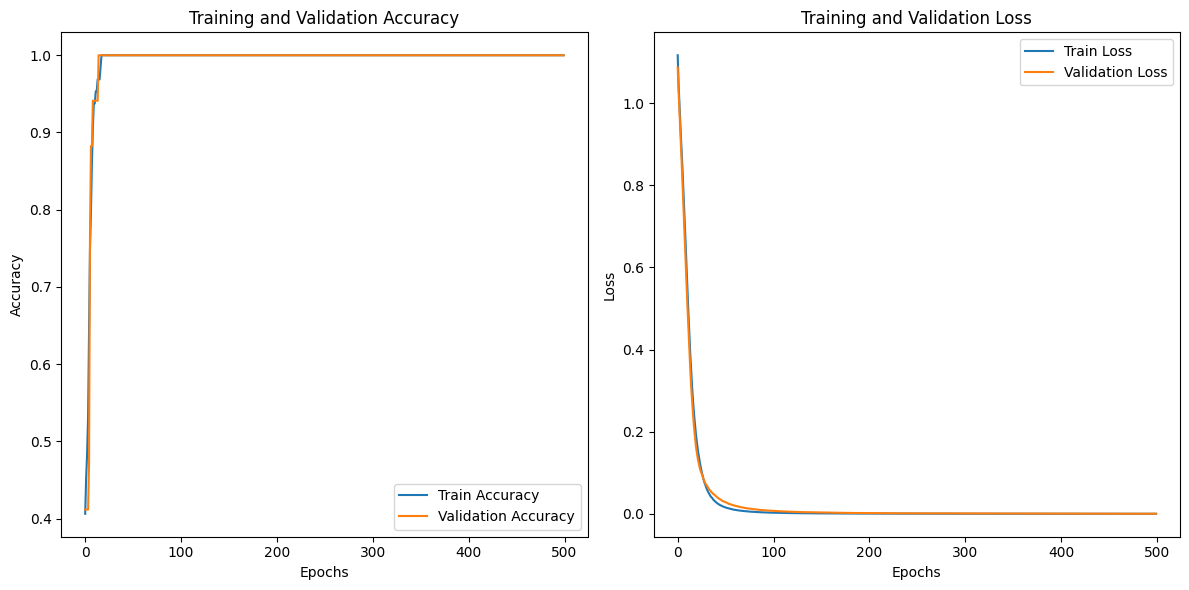

In [12]:
# Plot training and validation accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


1/1 [==============================] - 0s 12ms/step


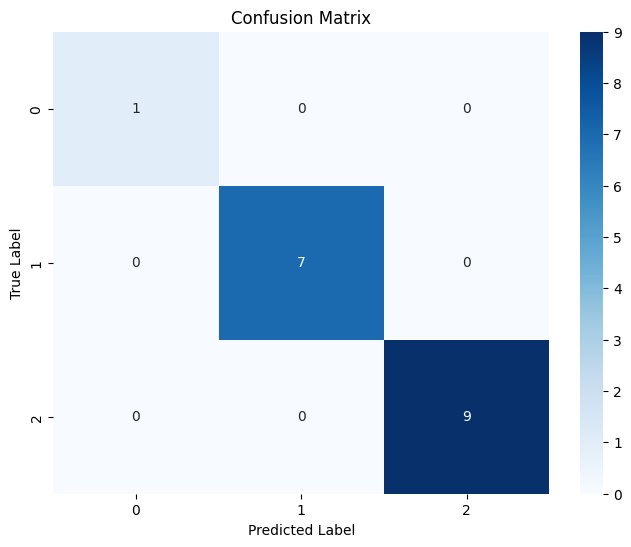

In [14]:
# Make predictions on the test data
y_pred = model.predict(X_test)

# Convert the one-hot encoded predictions and true labels into class indices
y_pred_classes = np.argmax(y_pred, axis=1)  # Predicted class indices
y_true_classes = np.argmax(y_test, axis=1)  # True class indices

# Generate the confusion matrix
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [16]:
# Generate the classification report
report = classification_report(y_true_classes, y_pred_classes)

# Print the classification report
print(report)


              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         7
           2       1.00      1.00      1.00         9

    accuracy                           1.00        17
   macro avg       1.00      1.00      1.00        17
weighted avg       1.00      1.00      1.00        17



In [17]:
# Save the model and preprocessor
model.save('question_type_model.h5')
joblib.dump(preprocessor, 'preprocessor.pkl')  


/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


['preprocessor.pkl']